In [19]:
# Data source comming from
# Hough, I. (2026). GEOS-Chem-IGE/hough2026_atmo-plast-emis_harmonize: v1.0.1 (Version v1.0.1) [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.23046811
# Dataset downloaded from https://github.com/GEOS-Chem-IGE/hough2026_atmo-plast-emis_harmonize/commit/a009a98f37adb85be02b9f3cf7c3de095ce3f444


In [20]:
from pandas import read_csv
import pandas as pd
import matplotlib.pyplot as plt
# Ensure the notebook directory is on Python's import path
import sys
from pathlib import Path
wd = "/home/rebouda/Documents/Git/openreprolab_2026-2027/labs/01_ABC-of-repro-numerical-science"
# set working directory to the notebook directory
import os
os.chdir(wd)
sys.path.insert(0, wd)
from lab01utils import download_file_from_github

In [2]:
# download the data file from the GitHub repository

repository = "GEOS-Chem-IGE/hough2026_atmo-plast-emis_harmonize"
commit = "a0ba5c3a6a5e0271ef9860ea8a5f8b73fce0e44d" # "6dba83595ce855fd16a5b4d8fc464c267b74c500" # "a009a98f37adb85be02b9f3cf7c3de095ce3f444"
filepath = "data/processed/obs_evangelou2026-revised.csv"

download_file_from_github(repository, commit, filepath) # not working because not recognised as a function, but the code is there

start downloading function:
Removed existing file: obs_evangelou2026-revised.csv
https://raw.githubusercontent.com/GEOS-Chem-IGE/hough2026_atmo-plast-emis_harmonize/a0ba5c3a6a5e0271ef9860ea8a5f8b73fce0e44d/data/processed/obs_evangelou2026-revised.csv
Downloaded file: obs_evangelou2026-revised.csv


In [16]:
data = read_csv(wd + "/" + "obs_evangelou2026-revised.csv", index_col=0, infer_datetime_format=True)

/tmp/ipykernel_47878/3737849753.py:1: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  data = read_csv(wd + "/" + "obs_evangelou2026-revised.csv", index_col=0, infer_datetime_format=True)


In [21]:
data.start_date = pd.to_datetime(data.start_date)

In [26]:
data.start_date.dt.year

author
Abbasi          2017
Abbasi          2019
Akhbarizadeh    2017
Allen           2018
Allen           2017
                ... 
Zhang           2021
Zhang           2021
Zhang           2021
Zhang           2021
Zhang           2021
Name: start_date, Length: 295, dtype: int32

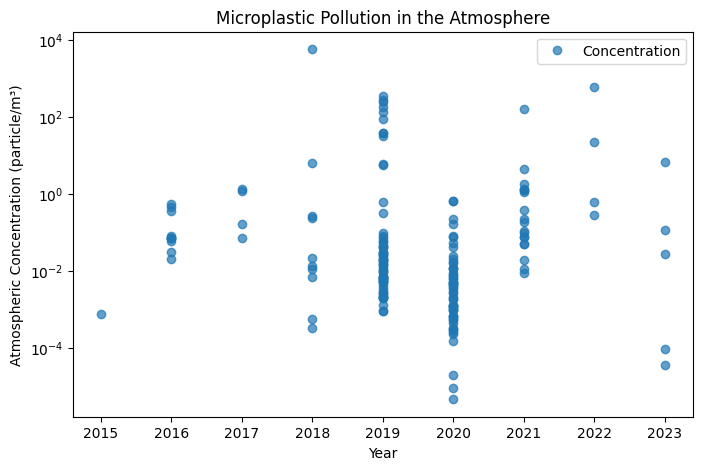

In [30]:
# plot the atmospheric concentration of microplastics as a function of year
plt.figure(figsize=(8, 5))
plt.plot(data.start_date.dt.year[data.measure == "concentration"], data.number[data.measure == "concentration"], 'o', alpha=0.7, label='Concentration')
plt.yscale('log')
plt.xlabel('Year')
plt.ylabel('Atmospheric Concentration (particle/m³)')
plt.title('Microplastic Pollution in the Atmosphere')
plt.legend()
plt.show()

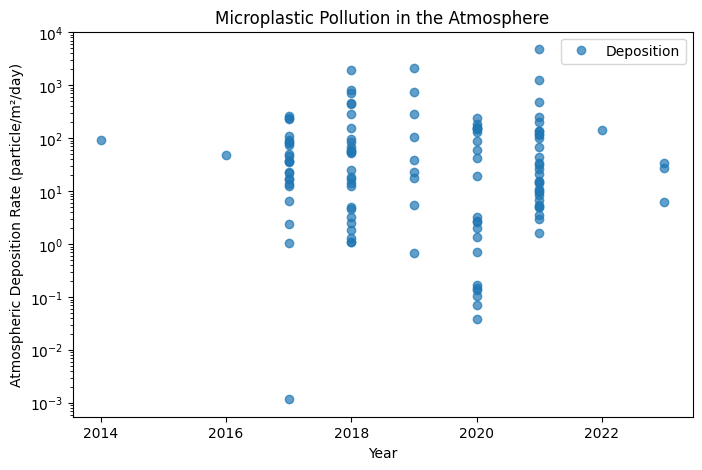

In [32]:
# plot the atmospheric deposition rate of microplastics as a function of year
plt.figure(figsize=(8, 5))
plt.plot(data.start_date.dt.year[data.measure == "deposition"], data.number[data.measure == "deposition"], 'o', alpha=0.7, label='Deposition')
plt.yscale('log')
plt.xlabel('Year')
plt.ylabel('Atmospheric Deposition Rate (particle/m²/day)')
plt.title('Microplastic Pollution in the Atmosphere')
plt.legend()
plt.show()

In [34]:
# Calculate the average plastic concentration
conc_avg = data.number[data.measure == "concentration"].mean()

# Calculate the average plastic deposition
dep_avg = data.number[data.measure == "deposition"].mean()

print(f"Average atmospheric microplastics composition = {conc_avg:.0f} particles/m3")
print(f"Average microplastics deposition rate = {dep_avg:.0f} particles/m2/d")

Average atmospheric microplastics composition = 45 particles/m3
Average microplastics deposition rate = 169 particles/m2/d
